In [14]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "./microcensus_filter/microcensus_ne_weekday_trips.csv"

# Grupperer transportmidler (wmittel) i hovedkategorier
MZ_MODE_MAP = {
    1: 'other',       # Flugzeug
    2: 'pt',       # bahn
    3: 'pt',      # postauto
    4: 'other',        # schiff
    5: 'pt',        # tram
    6: 'pt',        # bus
    7: 'pt',         # sonstiger oec
    8: 'other',         # reisecar
    9: 'car',         # auto
    10: 'other',     # lastwagen
    11: 'car_passenger',     # Taxi
    12: 'car',      # motorrad
    13: 'moped',      # mofa
    14: 'bike',      # velo
    15: 'walk',      # fuss
    16: 'other',      # ahrzeugähnliche Geräte
    17: 'other',      # anderes, weiss nicht, keine Antwort
    
}

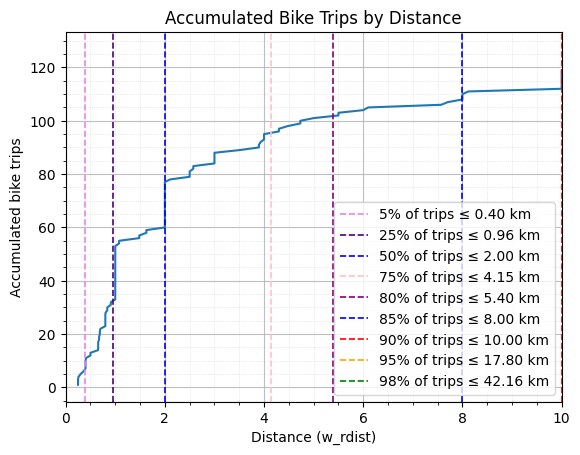

In [15]:
df = pd.read_csv(file_path)
# Map transport modes to main categories
df['mode'] = df['wmittel'].map(MZ_MODE_MAP)

# Filter bike trips and sort by distance
bike_trips = df[df['mode'] == 'bike'].sort_values('w_rdist')

# Accumulate bike trips by distance
bike_trips['cumulative_trips'] = np.arange(1, len(bike_trips) + 1)

# Plot accumulated bike trips vs distance
plt.plot(bike_trips['w_rdist'], bike_trips['cumulative_trips'])
plt.xlabel('Distance (w_rdist)')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Distance')
# Set maximum x-axis value (adjust as needed)
max_x = 10

plt.xlim(0, max_x)

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)


# Vertical lines at 85%, 90%, 95% and 98% of accumulated bike trips
for pct, color in [(5, 'violet'), (25, 'indigo'), (50, 'blue'), (75, 'pink'),(80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    dist_pct = np.percentile(bike_trips['w_rdist'], pct)
    plt.axvline(dist_pct, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {dist_pct:.2f} km')

plt.legend()


In [16]:
# Elevation difference (m): end elevation minus start elevation
df['elevation_diff'] = df['Z_Z_CH1903'] - df['S_Z_CH1903']

# Route distance converted from km to meters
df['distance_m'] = df['w_rdist'] * 1000

# Slope in percent (rise / run * 100), avoiding division by zero
df['slope_pct'] = np.where(
    df['distance_m'] > 0,
    df['elevation_diff'] / df['distance_m'] * 100,
    np.nan
)

# Slope in per-mille (common unit for road/rail gradients)
df['slope_permille'] = df['slope_pct'] * 10

df[['mode', 'w_rdist', 'S_Z_CH1903', 'Z_Z_CH1903', 'elevation_diff', 'slope_pct', 'slope_permille']].head()

,mode,w_rdist,S_Z_CH1903,Z_Z_CH1903,elevation_diff,slope_pct,slope_permille
0,walk,0.300,526.7,511.3,-15.4,-5.133333,-51.333333
1,walk,0.300,511.3,526.7,15.4,5.133333,51.333333
2,walk,0.300,526.7,511.3,-15.4,-5.133333,-51.333333
3,walk,0.300,511.3,526.7,15.4,5.133333,51.333333
4,car,2.596,473.2,542.7,69.5,2.677196,26.771957


Text(0, 0.5, 'Slope (per mille)')

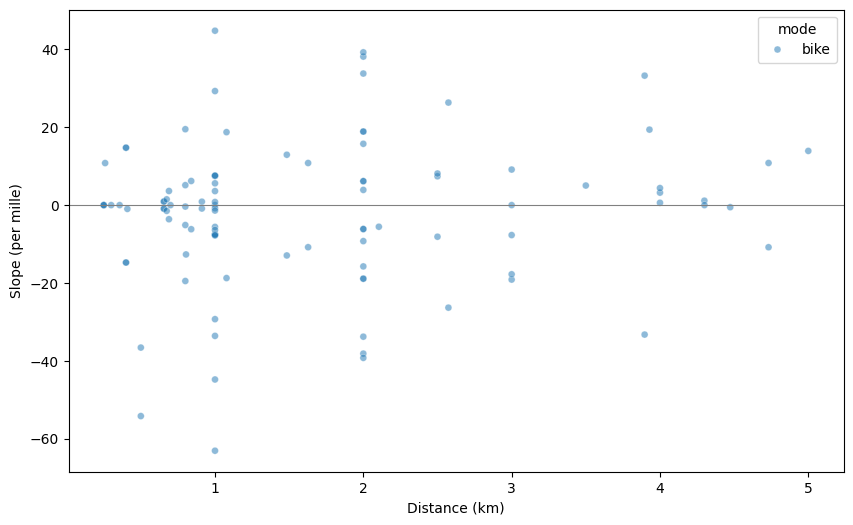

In [25]:
# Plot slope vs trip distance, colored by transport mode
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[(df['mode'] == 'bike') & (df["w_rdist"] < 5.4)].sort_values('w_rdist'), x='w_rdist', y='slope_permille', hue='mode', alpha=0.5, s=25)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('Distance (km)')
plt.ylabel('Slope (per mille)')

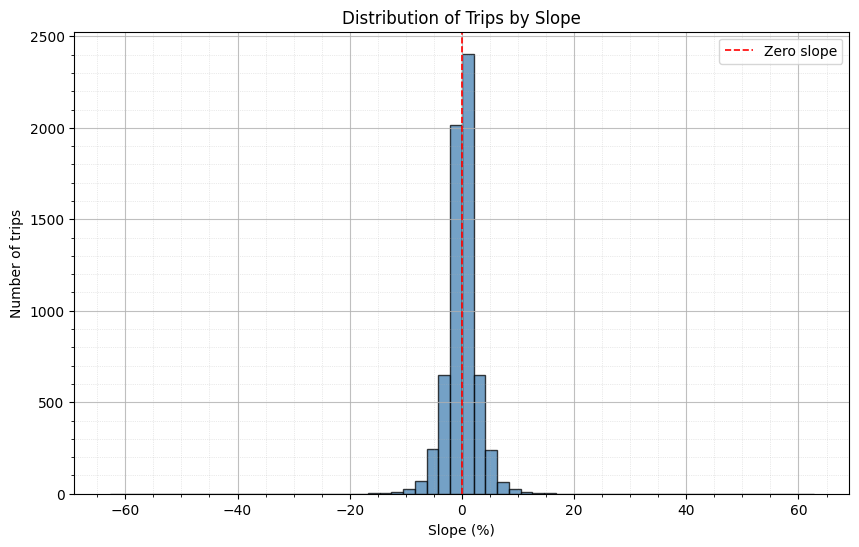

count    6433.000000
mean       -0.009297
std         3.174466
min       -62.800000
25%        -1.079668
50%         0.000000
75%         1.117142
max        62.800000
Name: slope_pct, dtype: float64


In [18]:
# Distribution of trips by slope (no distance involved)
plt.figure(figsize=(10, 6))
plt.hist(df['slope_pct'], bins=60, color='steelblue', edgecolor='black', alpha=0.75)
plt.axvline(0, color='red', linestyle='--', linewidth=1.2, label='Zero slope')
plt.xlabel('Slope (%)')
plt.ylabel('Number of trips')
plt.title('Distribution of Trips by Slope')
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)
plt.legend()
plt.show()

# Summary statistics of slope
print(df['slope_pct'].describe())

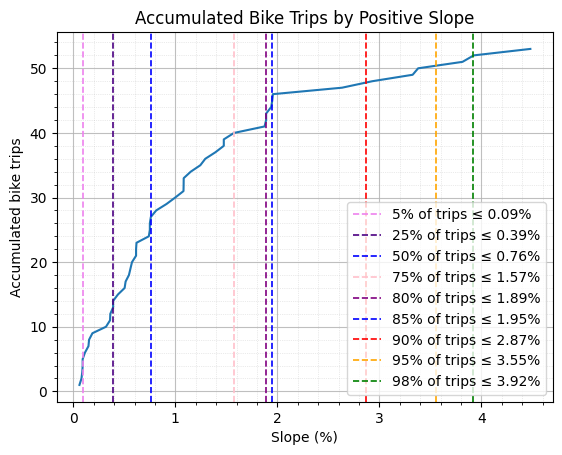

In [19]:
# Filter bike trips with positive slope and sort by slope
bike_trips_pos_slope = df[(df['mode'] == 'bike') & (df['slope_pct'] > 0)].sort_values('slope_pct')

# Accumulate bike trips by slope
bike_trips_pos_slope['cumulative_trips'] = np.arange(1, len(bike_trips_pos_slope) + 1)

# Plot accumulated bike trips vs slope
plt.plot(bike_trips_pos_slope['slope_pct'], bike_trips_pos_slope['cumulative_trips'])
plt.xlabel('Slope (%)')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Positive Slope')

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Vertical lines at percentiles of accumulated bike trips
for pct, color in [(5, 'violet'), (25, 'indigo'), (50, 'blue'), (75, 'pink'), (80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    slope_val = np.percentile(bike_trips_pos_slope['slope_pct'], pct)
    plt.axvline(slope_val, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {slope_val:.2f}%')

plt.legend()
plt.show()

In [20]:
relevant_trips_df = df[ (df['w_rdist'] <= 5.4) & (df['w_rdist'] >= 0.4)] #include 75% biking trips
#5% to 80% of slope values for biking trips


low_slope_trips_df = relevant_trips_df[(relevant_trips_df['slope_pct'] <= 0.76) & (relevant_trips_df['slope_pct'] >= 0.39)] # between 25% and 50% of slope values for biking trips
high_slope_trips_df = relevant_trips_df[(relevant_trips_df['slope_pct'] > 0.76) & (relevant_trips_df['slope_pct'] <= 1.57)] # above 50% of slope values for biking trips
avg_low_slope = low_slope_trips_df['slope_pct'].mean()
avg_high_slope = high_slope_trips_df['slope_pct'].mean()
lower_slop_bike_share = len(low_slope_trips_df[low_slope_trips_df['mode'] == 'bike']) / len(low_slope_trips_df)
high_slop_bike_share = len(high_slope_trips_df[high_slope_trips_df['mode'] == 'bike']) / len(high_slope_trips_df)


print(f"""
For this we are considering only trips with distance between 0.4 km and 5.4 km, which includes 75% of biking trips.
Within this range, we are looking at trips with slope between 0.39% and 1.57%, which includes 50% of biking trips.
This is divided into two groups: trips with slope between 0.39% and 0.76% (25% of biking trips) and trips with slope between 0.76% and 1.57% (25% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.

""")
print(f"Bike share for lower slope trips: {lower_slop_bike_share:.2%}")
print(f"Bike share for higher slope trips: {high_slop_bike_share:.2%}")
beta_slope1 = (high_slop_bike_share - lower_slop_bike_share)/lower_slop_bike_share / (avg_high_slope - avg_low_slope)/avg_low_slope
beta_slope = (high_slop_bike_share - lower_slop_bike_share)/ (avg_high_slope - avg_low_slope)
print(f"Beta coefficient for slope: {beta_slope:.5f}")
print(f"Beta coeffcient for slope using new model: {beta_slope1:.5f}")


For this we are considering only trips with distance between 0.4 km and 5.4 km, which includes 75% of biking trips.
Within this range, we are looking at trips with slope between 0.39% and 1.57%, which includes 50% of biking trips.
This is divided into two groups: trips with slope between 0.39% and 0.76% (25% of biking trips) and trips with slope between 0.76% and 1.57% (25% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.


Bike share for lower slope trips: 3.73%
Bike share for higher slope trips: 2.60%
Beta coefficient for slope: -0.01983
Beta coeffcient for slope using new model: -0.94430


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_70245/2429046437.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  relevant_trips_df['slope_interval'] = pd.cut(relevant_trips_df['slope_pct'], bins=slope_bins)


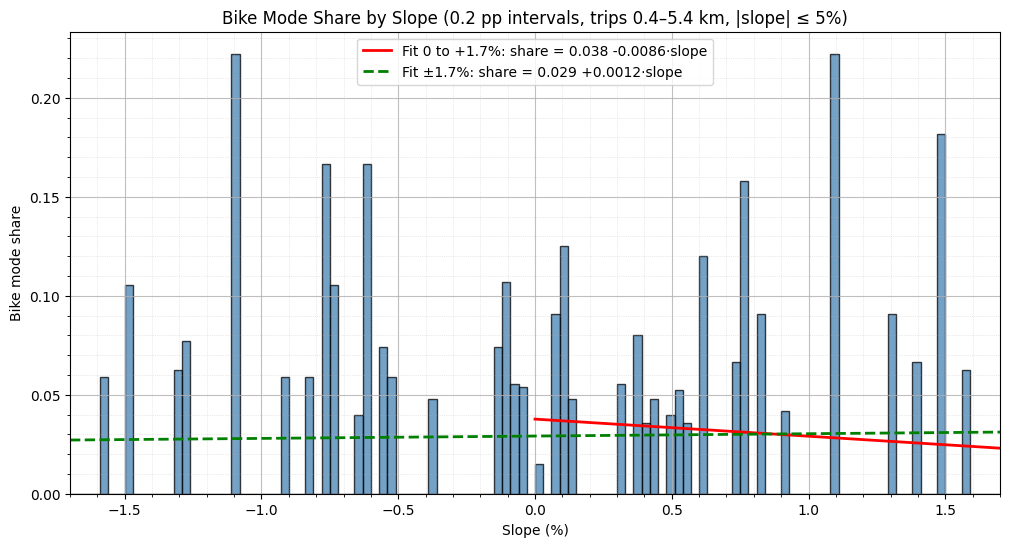

Positive-slope regression (0 to 1.7%): slope = -0.0086, intercept = 0.0377
Full-range regression (±1.7%): slope = 0.0012, intercept = 0.0291


,slope_interval,bike_share,n_trips,slope_mid
201,"(-1.71, -1.68]",0.000000,7,-1.695
202,"(-1.68, -1.65]",0.000000,7,-1.665
203,"(-1.65, -1.62]",0.000000,10,-1.635
204,"(-1.62, -1.59]",0.000000,14,-1.605
205,"(-1.59, -1.56]",0.058824,17,-1.575
...,...,...,...,...
310,"(1.56, 1.59]",0.062500,16,1.575
311,"(1.59, 1.62]",0.000000,15,1.605
312,"(1.62, 1.65]",0.000000,8,1.635
313,"(1.65, 1.68]",0.000000,7,1.665


In [24]:
# Divide relevant trips into slope intervals of 0.2 percentage points
bin_width = .03
max_gradient = 1.7  # limit plot to ±5% slope
slope_bins = np.arange(
    np.floor(relevant_trips_df['slope_pct'].min() / bin_width) * bin_width,
    np.ceil(relevant_trips_df['slope_pct'].max() / bin_width) * bin_width + bin_width,
    bin_width
)
relevant_trips_df['slope_interval'] = pd.cut(relevant_trips_df['slope_pct'], bins=slope_bins)

# Bike mode share and trip count per slope interval
bike_share_by_slope = (
    relevant_trips_df
    .assign(is_bike=relevant_trips_df['mode'] == 'bike')
    .groupby('slope_interval', observed=True)
    .agg(bike_share=('is_bike', 'mean'), n_trips=('is_bike', 'size'))
    .reset_index()
)
# .map on a categorical column keeps the categorical dtype -> convert to float
bike_share_by_slope['slope_mid'] = bike_share_by_slope['slope_interval'].map(lambda iv: iv.mid).astype(float)

# Restrict to intervals within ±5% gradient
bike_share_limited = bike_share_by_slope[bike_share_by_slope['slope_mid'].abs() <= max_gradient]

# Plot bike share per slope interval
plt.figure(figsize=(12, 6))
plt.bar(bike_share_limited['slope_mid'], bike_share_limited['bike_share'],
        width=bin_width, color='steelblue', edgecolor='black', alpha=0.75)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlim(-max_gradient, max_gradient)
plt.xlabel('Slope (%)')
plt.ylabel('Bike mode share')
plt.title('Bike Mode Share by Slope (0.2 pp intervals, trips 0.4–5.4 km, |slope| ≤ 5%)')
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Regression 1: positive slopes only (0 to max_gradient)
pos = bike_share_limited[bike_share_limited['slope_mid'] >= 0]
slope_pos, intercept_pos = np.polyfit(pos['slope_mid'], pos['bike_share'], 1)
x_pos = np.linspace(0, max_gradient, 100)
plt.plot(x_pos, intercept_pos + slope_pos * x_pos, color='red', linewidth=2,
         label=f'Fit 0 to +{max_gradient}%: share = {intercept_pos:.3f} {slope_pos:+.4f}·slope')

# Regression 2: full range (-max_gradient to max_gradient)
slope_all, intercept_all = np.polyfit(bike_share_limited['slope_mid'], bike_share_limited['bike_share'], 1)
x_all = np.linspace(-max_gradient, max_gradient, 100)
plt.plot(x_all, intercept_all + slope_all * x_all, color='green', linewidth=2, linestyle='--',
         label=f'Fit ±{max_gradient}%: share = {intercept_all:.3f} {slope_all:+.4f}·slope')

plt.legend()
plt.show()

print(f"Positive-slope regression (0 to {max_gradient}%): slope = {slope_pos:.4f}, intercept = {intercept_pos:.4f}")
print(f"Full-range regression (±{max_gradient}%): slope = {slope_all:.4f}, intercept = {intercept_all:.4f}")

bike_share_limited